In [2]:
import pandas as pd, numpy as np

sales = pd.read_parquet(r"D:\retailpulse\retailpulse_sales_clean.parquet",
    columns=["customer_id", "receipt_id", "date", "total_value", "discount_pct", "channel"])
sales["customer_id"] = sales["customer_id"].astype(str)
sales["is_online"] = (sales["channel"] == "Online")

CUT = pd.Timestamp("2025-10-01")      # "today" for the model
W = pd.Timedelta(days=92)             # one window = 92 days (Jul-Sep, then Oct-Dec)

hist   = sales[sales["date"] < CUT]                                    # known on the cut-off day
future = sales[(sales["date"] >= CUT) & (sales["date"] < CUT + W)]     # what happens next

def receipts(df, start, end):
    d = df[(df["date"] >= start) & (df["date"] < end)]
    return d.groupby("customer_id")["receipt_id"].nunique()

feat = hist.groupby("customer_id").agg(
    first_purchase=("date", "min"), last_purchase=("date", "max"),
    frequency=("receipt_id", "nunique"), monetary=("total_value", "sum"),
    avg_discount=("discount_pct", "mean"), online_share=("is_online", "mean"),
)
feat["recency_days"]    = (CUT - feat["last_purchase"]).dt.days
feat["avg_order_value"] = feat["monetary"] / feat["frequency"]
feat["usual_gap_days"]  = (feat["last_purchase"] - feat["first_purchase"]).dt.days / (feat["frequency"] - 1).clip(lower=1)
feat["silence_ratio"]   = feat["recency_days"] / feat["usual_gap_days"]

feat["last_30"] = receipts(hist, CUT - pd.Timedelta(days=30), CUT).reindex(feat.index, fill_value=0)
feat["last_92"] = receipts(hist, CUT - W, CUT).reindex(feat.index, fill_value=0)
feat["prev_92"] = receipts(hist, CUT - 2 * W, CUT - W).reindex(feat.index, fill_value=0)
feat["trend_92"] = (feat["last_92"] - feat["prev_92"]) / feat["prev_92"].clip(lower=1)

# the label: purchases in the next 92 days fell by more than 10% compared with the last 92 days
feat["next_92"] = receipts(future, CUT, CUT + W).reindex(feat.index, fill_value=0)
feat["churn"] = (feat["next_92"] < 0.9 * feat["last_92"]).astype(int)

# add customer details
folder = r"D:\retailpulse\datarawsynthetic\retail_contaminated_dataset"
cust = pd.read_csv(folder + r"\customer_master.csv")[["cust_id", "age", "gender", "loyalty_segment", "preferred_channel"]]
feat = feat.reset_index().merge(cust, left_on="customer_id", right_on="cust_id").drop(columns="cust_id")

print(feat.shape)
print(feat["churn"].value_counts(normalize=True).round(3))
feat.to_parquet(r"D:\retailpulse\churn_dataset.parquet", index=False)

(10000, 21)
churn
0    0.866
1    0.134
Name: proportion, dtype: float64


In [3]:
pip install xgboost shap

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

feat = pd.read_parquet(r"D:\retailpulse\churn_dataset.parquet")

# columns the model must NOT see: IDs, dates, and the answer (next_92 and churn)
drop = ["customer_id", "first_purchase", "last_purchase", "next_92", "churn"]
X = pd.get_dummies(feat.drop(columns=drop), columns=["gender", "loyalty_segment", "preferred_channel"])
y = feat["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)    # 80% to learn, 20% to test
print(X_train.shape, X_test.shape)

(8000, 23) (2000, 23)


In [5]:
rf = RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced",
                            random_state=42, n_jobs=-1).fit(X_train, y_train)

xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                    colsample_bytree=0.8, eval_metric="auc", random_state=42,
                    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum()).fit(X_train, y_train)

def evaluate(name, scores):
    top = np.argsort(scores)[::-1][:int(len(scores) * 0.2)]     # the 20% of customers ranked riskiest
    prec = y_test.values[top].mean()                            # how many of them really churned
    print(f"{name}: ROC-AUC = {roc_auc_score(y_test, scores):.3f} | precision@top20% = {prec:.3f}")

evaluate("Random Forest", rf.predict_proba(X_test)[:, 1])
evaluate("XGBoost", xgb.predict_proba(X_test)[:, 1])
evaluate("Simple rule (only trend_92)", -X_test["trend_92"].values)
print("Share of churners in the test set (random guessing would score this):", round(y_test.mean(), 3))

Random Forest: ROC-AUC = 0.836 | precision@top20% = 0.400
XGBoost: ROC-AUC = 0.835 | precision@top20% = 0.405
Simple rule (only trend_92): ROC-AUC = 0.263 | precision@top20% = 0.028
Share of churners in the test set (random guessing would score this): 0.134


In [6]:
single = pd.Series({c: roc_auc_score(y_test, X_test[c].astype(float)) for c in X_test.columns})
print("Single columns, farthest from 0.5 first:")
print(single.loc[(single - 0.5).abs().sort_values(ascending=False).index].head(8).round(3))

imp = pd.Series(xgb.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nXGBoost feature importance:")
print(imp.head(8).round(3))

Single columns, farthest from 0.5 first:
trend_92                  0.737
prev_92                   0.405
loyalty_segment_Bronze    0.587
silence_ratio             0.414
monetary                  0.419
usual_gap_days            0.581
frequency                 0.420
last_92                   0.563
dtype: float64

XGBoost feature importance:
loyalty_segment_Bronze      0.170
loyalty_segment_Silver      0.132
trend_92                    0.107
last_92                     0.079
loyalty_segment_Platinum    0.058
loyalty_segment_Gold        0.054
frequency                   0.044
usual_gap_days              0.036
dtype: float32


In [7]:
def try_label(name, y_new, Xuse=X):
    Xtr, Xte, ytr, yte = train_test_split(Xuse, y_new, test_size=0.2, stratify=y_new, random_state=42)
    m = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                      colsample_bytree=0.8, random_state=42,
                      scale_pos_weight=(ytr == 0).sum() / (ytr == 1).sum()).fit(Xtr, ytr)
    p = m.predict_proba(Xte)[:, 1]
    top = np.argsort(p)[::-1][:int(len(p) * 0.2)]
    print(f"{name}: churners={y_new.mean():.3f} | AUC={roc_auc_score(yte, p):.3f} | precision@top20%={yte.values[top].mean():.3f}")

# A: the label you already have
try_label("A: next < 90% of last 92 days", feat["churn"])

# B: compare with the average of the last TWO windows (less affected by one lucky window)
base_2 = (feat["last_92"] + feat["prev_92"]) / 2
try_label("B: next < 90% of 2-window average", (feat["next_92"] < 0.9 * base_2).astype(int))

# E: compare with the SAME months one year earlier (also handles the Nov-Dec peak)
yoy = receipts(hist, CUT - pd.Timedelta(days=365), CUT - pd.Timedelta(days=365) + W)
yoy = yoy.reindex(feat["customer_id"], fill_value=0).values
yE = pd.Series((feat["next_92"].values < 0.9 * yoy).astype(int), index=feat.index)
try_label("E: next < 90% of same months last year", yE, X.assign(same_months_last_year=yoy))

A: next < 90% of last 92 days: churners=0.135 | AUC=0.835 | precision@top20%=0.405
B: next < 90% of 2-window average: churners=0.103 | AUC=0.783 | precision@top20%=0.275
E: next < 90% of same months last year: churners=0.289 | AUC=0.818 | precision@top20%=0.647


In [8]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

XE  = X.assign(same_months_last_year=yoy)
cv  = StratifiedKFold(5, shuffle=True, random_state=42)
spw = (yE == 0).sum() / (yE == 1).sum()

configs = {
    "xgb_small":     XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw, random_state=42),
    "xgb_medium":    XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw, random_state=42),
    "xgb_deeper":    XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw, random_state=42),
    "random_forest": RandomForestClassifier(n_estimators=400, max_depth=8, min_samples_leaf=20, class_weight="balanced", random_state=42, n_jobs=-1),
}
for name, m in configs.items():
    auc = cross_val_score(m, XE, yE, cv=cv, scoring="roc_auc")
    print(f"{name}: AUC {auc.mean():.3f} (+/- {auc.std():.3f})")

xgb_small: AUC 0.823 (+/- 0.007)
xgb_medium: AUC 0.822 (+/- 0.006)
xgb_deeper: AUC 0.816 (+/- 0.006)
random_forest: AUC 0.804 (+/- 0.008)


ROC-AUC: 0.822 | precision@top20%: 0.658 | base rate: 0.289


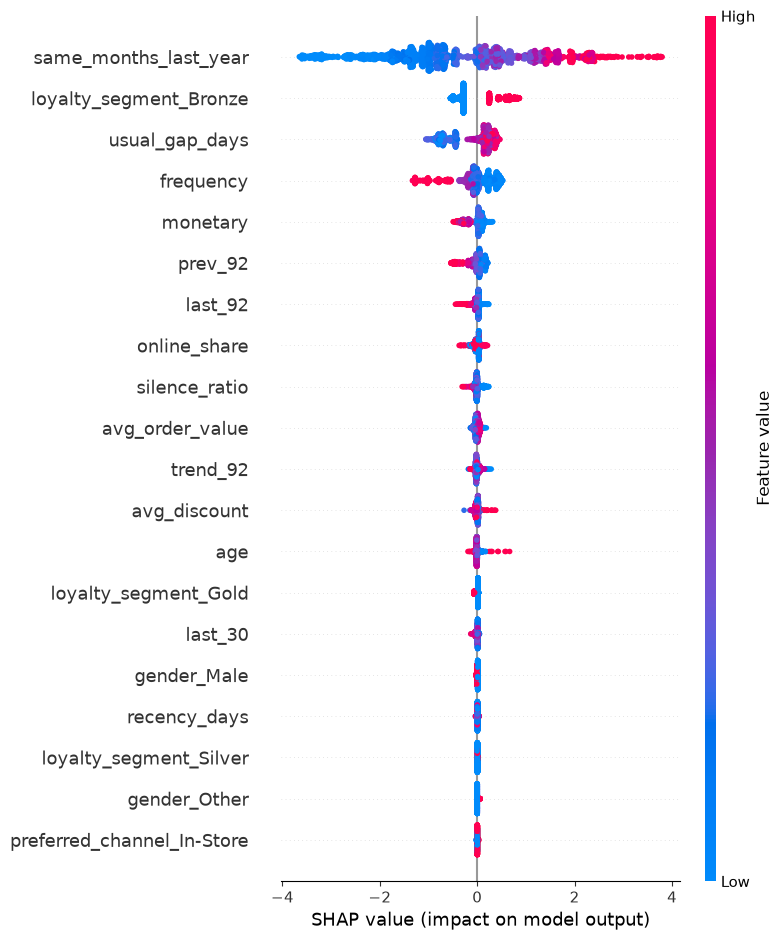

In [9]:
import shap, matplotlib.pyplot as plt

XF = XE.astype(float)
Xtr, Xte, ytr, yte = train_test_split(XF, yE, test_size=0.2, stratify=yE, random_state=42)

final = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8,
                      colsample_bytree=0.8, random_state=42,
                      scale_pos_weight=(ytr == 0).sum() / (ytr == 1).sum()).fit(Xtr, ytr)

p = final.predict_proba(Xte)[:, 1]
top = np.argsort(p)[::-1][:int(len(p) * 0.2)]
print("ROC-AUC:", round(roc_auc_score(yte, p), 3),
      "| precision@top20%:", round(yte.values[top].mean(), 3),
      "| base rate:", round(yte.mean(), 3))

# SHAP: which columns push a customer towards "churn"?
sv = shap.TreeExplainer(final).shap_values(Xte)
shap.summary_plot(sv, Xte, show=False)
plt.savefig(r"D:\retailpulse\app_data\shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()


In [10]:
from sklearn.model_selection import cross_val_predict

model_cv = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8,
                         colsample_bytree=0.8, random_state=42, scale_pos_weight=spw)
proba = cross_val_predict(model_cv, XF, yE, cv=cv, method="predict_proba")[:, 1]   # every score comes from a model that never saw that customer

scores = pd.DataFrame({"customer_id": feat["customer_id"], "churn_probability": proba.round(3)})
scores["risk_band"] = pd.qcut(scores["churn_probability"], [0, 0.6, 0.85, 1], labels=["Low", "Medium", "High"])
seg = pd.read_csv(r"D:\retailpulse\customer_table.csv")[["customer_id", "segment"]]
scores = scores.merge(seg, on="customer_id")
scores.to_csv(r"D:\retailpulse\app_data\churn_scores.csv", index=False)
print(scores["risk_band"].value_counts())

risk_band
Low       6004
Medium    2499
High      1497
Name: count, dtype: int64
